# Prisuppskattning av hus i King County

**Företag:** JSSM Realstate
**Grupp:** Jessika, Saji, Shiann och Milena
**Datum:** 2026-10-14

## 1. Affärsfall

**Organisationen:** JSSM Realstate är ett värderingsföretag i Seattle-området, grundat av Saji, Milena, Jessika och Shiann. Vi hjälper säljare, köpare och mäklare att bedöma rimliga huspriser.

**Varför behövs avancerad analys?**
Idag görs prisbedömningar ofta manuellt, vilket är långsamt och subjektivt. Två värderare kan komma fram till olika priser för samma hus. Med data från över 21 000 tidigare försäljningar kan vi i stället:
- **förklara** vad som faktiskt driver priset och hur säkra vi kan vara på det (avancerad statistik), och
- **förutsäga** priset på nya hus med bra träffsäkerhet (maskininlärning).

**Affärsproblemet:**
> Hur kan vi uppskatta ett rimligt försäljningspris för ett hus utifrån dess egenskaper, som storlek, kvalitet, skick och läge, och förklara för kunden varför priset blir som det blir?

**Vad blir nyttan?**
- Säljare prissätter rätt och undviker att sälja för billigt eller att huset blir stående osålt.
- Köpare undviker att överbetala.
- Vi kan göra värderingar snabbare, mer enhetligt och med ett tydligt, förklarbart underlag.

### Vårt tillvägagångssätt: två modeller för två syften

| Syfte | Metod | Fråga den svarar på |
|---|---|---|
| **Förklara** (statistisk inferens) | Linjär regression (OLS) med p-värden och konfidensintervall | *Vad påverkar priset, hur mycket, och är sambandet verkligt?* |
| **Förutsäga** (prediktiv analys) | Random Forest | *Vad kommer ett nytt hus att kosta?* |

Båda tränas på samma träningsdata och utvärderas på samma testdata, så jämförelsen blir rättvis.

In [1]:
# Kör den här cellen bara om något paket saknas (ta bort #-tecknet först).
# %pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

In [2]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [3]:
import statsmodels.api as sm
print(sm.__version__)

0.15.0


In [4]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\shian\anaconda3\envs\House_Sales\python.exe
3.14.8 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:25:10) [MSC v.1942 64 bit (AMD64)]


In [5]:
import sys
!{sys.executable} -m pip install statsmodels

In [6]:
# --- Importera de bibliotek vi behöver ---
import numpy as np                              # matematik och arrayer
import pandas as pd                             # tabeller (DataFrame)
import matplotlib.pyplot as plt                 # diagram
import seaborn as sns                           # snyggare diagram ovanpå matplotlib
from matplotlib.ticker import FuncFormatter     # för att formatera siffrorna på axlarna

from scipy import stats                         # hypotestest (t-test, Mann-Whitney, Spearman)
import statsmodels.api as sm                    # statistisk regression (OLS) med p-värden
from statsmodels.stats.diagnostic import het_breuschpagan                      # test för ojämn spridning
from statsmodels.stats.outliers_influence import variance_inflation_factor     # test för överlappande variabler

from sklearn.model_selection import train_test_split, cross_val_score  # dela data, korsvalidering
from sklearn.ensemble import RandomForestRegressor                     # Random Forest-modellen
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # mått på modellens fel

# --- Gemensamt utseende på alla diagram ---
sns.set_theme(style="whitegrid")                # ljus bakgrund med svagt rutnät
BLÅ, ORANGE, GRÅ = "#0072B2", "#E69F00", "#6B7280"   # färgblindsäkra färger. Random Forest = blå, OLS = orange

def miljoner(x, _):
    # Gör om 1500000 till "1.5" så att axeln slipper skriva "1e6"
    return f"{x/1e6:.1f}"

def tusental(x, _):
    # Gör om 250000 till "250" (tusen USD)
    return f"{x/1e3:.0f}"

## 2. Datan

Vi använder datasetet **King County House Sales** med husförsäljningar i Seattle-området mellan **maj 2014 och maj 2015**. Varje rad är en såld bostad och varje kolumn är en egenskap hos huset.

| Kolumn | Betydelse |
|---|---|
| price | Försäljningspris i USD (**det vi vill förutsäga**) |
| bedrooms / bathrooms | Antal sovrum / badrum |
| sqft_living | Boyta i kvadratfot (1 kvadratfot = 0,093 m²) |
| sqft_lot | Tomtyta i kvadratfot |
| floors | Antal våningar |
| waterfront | 1 = vid vatten, 0 = inte |
| view | Hur bra utsikt huset har (0 till 4) |
| condition | Husets skick (1 till 5) |
| grade | Kvalitet på bygge och design (1 till 13) |
| sqft_above / sqft_basement | Boyta över marken / i källare |
| yr_built / yr_renovated | Byggår / renoveringsår (0 = aldrig renoverat) |
| zipcode, lat, long | Postnummer och koordinater (läge) |
| sqft_living15 / sqft_lot15 | Boyta och tomt hos de 15 närmaste grannarna |
| id, date | Husets id och försäljningsdatum |

In [7]:
# Läs in CSV-filen till en tabell som vi kallar df (DataFrame)
df = pd.read_csv("kc_house_data.csv")

print("Antal rader och kolumner:", df.shape)   # (rader, kolumner)
df.head()                                       # visa de första 5 raderna

Antal rader och kolumner: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 3. Kontroll och rensning av datan

Innan vi analyserar något kontrollerar vi att datan är hel och rimlig.

In [8]:
# Saknade värden: summan av alla tomma celler i hela tabellen
print("Saknade värden totalt:", df.isnull().sum().sum())

# Dubbletter: rader som är exakt likadana
print("Helt identiska rader:", df.duplicated().sum())

# Hus som sålts mer än en gång har samma id på flera rader
print("Rader med upprepat id (huset sålt flera gånger):", df["id"].duplicated().sum())

# Vilken tidsperiod täcker datan?
datum = pd.to_datetime(df["date"])
print("Period:", datum.min().date(), "till", datum.max().date())

# Sammanfattande statistik för några nyckelvariabler: min, median, max m.m.
df[["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot"]].describe().round(0)

Saknade värden totalt: 0
Helt identiska rader: 0
Rader med upprepat id (huset sålt flera gånger): 177
Period: 2014-05-02 till 2015-05-27


,price,bedrooms,bathrooms,sqft_living,sqft_lot
count,21613.0,21613.0,21613.0,21613.0,21613.0
mean,540088.0,3.0,2.0,2080.0,15107.0
std,367127.0,1.0,1.0,918.0,41421.0
min,75000.0,0.0,0.0,290.0,520.0
25%,321950.0,3.0,2.0,1427.0,5040.0
50%,450000.0,3.0,2.0,1910.0,7618.0
75%,645000.0,4.0,2.0,2550.0,10688.0
max,7700000.0,33.0,8.0,13540.0,1651359.0


In [9]:
# Titta på hus med extremt många sovrum. Finns det något som ser konstigt ut?
df.loc[df["bedrooms"] >= 10, ["bedrooms", "bathrooms", "sqft_living", "price"]]

,bedrooms,bathrooms,sqft_living,price
8757,11,3.00,3000,520000.0
13314,10,5.25,4590,1148000.0
15161,10,2.00,3610,650000.0
15870,33,1.75,1620,640000.0
19254,10,3.00,2920,660000.0


**Vad vi hittade:**
- **Inga saknade värden** och **inga helt identiska rader**.
- **177 rader har ett id som förekommer flera gånger.** Det är hus som sålts två gånger under perioden. Det är riktiga, separata försäljningar, så vi behåller dem.
- **Ett hus har 33 sovrum men bara 1 620 kvadratfot boyta och 1,75 badrum.** Det är nästan säkert ett skrivfel, så vi tar bort just den raden. Husen med 10 och 11 sovrum är orimliga i förhållande till sin storlek, men inte omöjliga, så de får vara kvar.

**Vad vi ändrar och skapar:**
- `date` görs om från text till riktigt datum.
- `house_age` = husets ålder när det såldes (försäljningsår minus byggår).
- `renovated` = 1 om huset renoverats, annars 0.
- `has_basement` = 1 om huset har källare, annars 0.

**Vad vi väljer bort i modellerna:**
- `id` och `date`: de beskriver inte huset.
- `zipcode`: ett postnummer är en kategori, inte ett tal. Läget fångas redan av `lat` och `long`.
- `sqft_above` och `sqft_basement`: tillsammans är de exakt lika med `sqft_living`. Skulle vi ta med alla tre blir regressionen matematiskt obestämd (perfekt multikollinearitet). Vi behåller `sqft_living` och `has_basement`.

In [10]:
# Gör om datum från text (t.ex. 20141013T000000) till ett riktigt datum
df["date"] = pd.to_datetime(df["date"])

# Ta bort huset med 33 sovrum (troligen ett skrivfel). .copy() ger en egen kopia att arbeta med.
df = df[df["bedrooms"] < 33].copy()

# Skapa nya variabler som kan hjälpa modellerna
df["house_age"] = df["date"].dt.year - df["yr_built"]       # husets ålder vid försäljning
df["renovated"] = (df["yr_renovated"] > 0).astype(int)      # 1 = renoverat, 0 = aldrig
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)  # 1 = har källare

print("Antal hus efter rensning:", len(df))

Antal hus efter rensning: 21612


## 4. Utforskning: hur ser priserna ut?

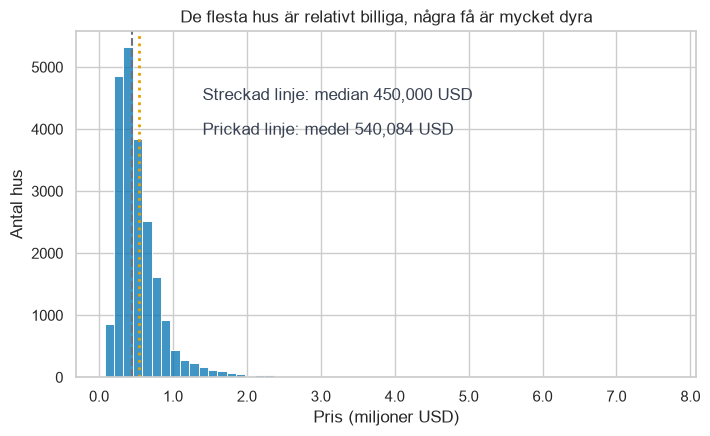

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Histogram: hur många hus hamnar i varje prisintervall (60 staplar)
sns.histplot(df["price"], bins=60, color=BLÅ, ax=ax)

# Lodräta linjer för median (mittersta huset) och medelvärde
median, medel = df["price"].median(), df["price"].mean()
ax.axvline(median, color=GRÅ, linestyle="--", linewidth=1.5)
ax.axvline(medel, color=ORANGE, linestyle=":", linewidth=2)
ax.text(1.4e6, ax.get_ylim()[1] * 0.80, f"Streckad linje: median {median:,.0f} USD", ha="left", color="#374151")
ax.text(1.4e6, ax.get_ylim()[1] * 0.70, f"Prickad linje: medel {medel:,.0f} USD", ha="left", color="#374151")

ax.xaxis.set_major_formatter(FuncFormatter(miljoner))   # visa pris i miljoner USD
ax.set_title("De flesta hus är relativt billiga, några få är mycket dyra")
ax.set_xlabel("Pris (miljoner USD)")
ax.set_ylabel("Antal hus")
plt.show()

**Vad ser vi?** Fördelningen har en lång svans åt höger: de flesta hus kostar 300 000 till 650 000 USD, men ett fåtal kostar flera miljoner. Därför är **medelvärdet högre än medianen** (ett fåtal dyra hus drar upp snittet). Det har två konsekvenser som vi återkommer till: vi bör använda tester som tål sneda fördelningar, och vi loggar priset i regressionen.

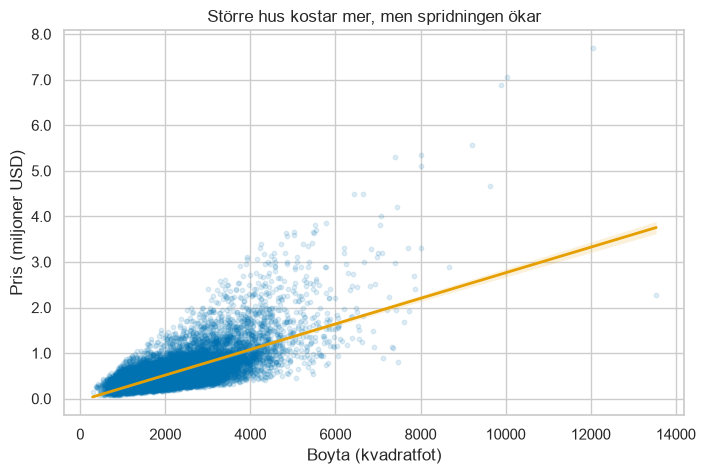

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

# Spridningsdiagram: varje punkt är ett hus. Låg alpha gör att täta områden syns tydligt.
# regplot ritar dessutom en rät trendlinje genom punkterna.
sns.regplot(data=df, x="sqft_living", y="price",
            scatter_kws=dict(alpha=0.12, s=10, color=BLÅ),
            line_kws=dict(color=ORANGE, linewidth=2), ax=ax)

ax.yaxis.set_major_formatter(FuncFormatter(miljoner))   # pris i miljoner USD
ax.set_title("Större hus kostar mer, men spridningen ökar")
ax.set_xlabel("Boyta (kvadratfot)")
ax.set_ylabel("Pris (miljoner USD)")
plt.show()

**Vad ser vi?** Ju större boyta, desto högre pris, och sambandet är tydligt. Men spridningen ökar med storleken: stora hus kan kosta allt från ett par hundra tusen till flera miljoner USD. Boyta ensam räcker alltså inte för att bestämma priset, så vi behöver fler egenskaper i modellen.

## 5. Statistiska tester: är sambanden verkliga eller slump?

Ett diagram kan visa en skillnad, men är den **verklig** eller kan den bero på slumpen? Det svarar hypotestest på.

**Fråga 1:** Kostar hus vid vatten mer än andra hus?
- **Nollhypotes (H0):** Det finns ingen skillnad i pris.
- **Alternativ (H1):** Det finns en skillnad.

Vi använder ett **p-värde**: sannolikheten att se en så stor skillnad om det egentligen inte fanns någon. Ett p-värde under 0,05 betyder att skillnaden sannolikt inte beror på slump.

Eftersom priserna är sneda använder vi **två tester**: Welchs t-test (jämför medelvärden) och Mann-Whitney U (jämför hela fördelningarna och kräver ingen normalfördelning). Vi lägger till ett **bootstrap-konfidensintervall** för skillnaden i medianpris.

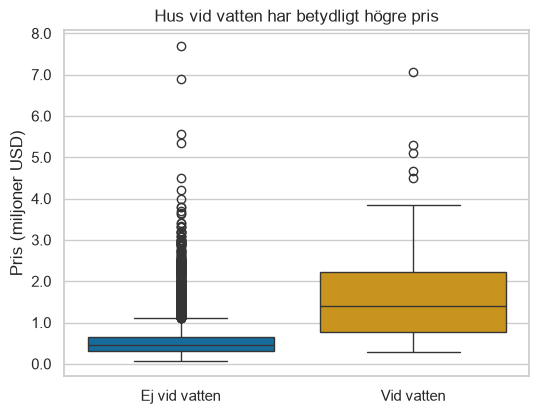

In [13]:
fig, ax = plt.subplots(figsize=(6, 4.5))

# Boxplot: lådan visar var mittersta 50 % av priserna ligger, strecket i mitten är medianen
sns.boxplot(data=df, x="waterfront", y="price", hue="waterfront",
            palette={0: BLÅ, 1: ORANGE}, legend=False, ax=ax)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Ej vid vatten", "Vid vatten"])
ax.yaxis.set_major_formatter(FuncFormatter(miljoner))
ax.set_title("Hus vid vatten har betydligt högre pris")
ax.set_xlabel("")
ax.set_ylabel("Pris (miljoner USD)")
plt.show()

In [14]:
# Dela upp priserna i två grupper
vatten = df.loc[df["waterfront"] == 1, "price"]
ej_vatten = df.loc[df["waterfront"] == 0, "price"]

# Welchs t-test: jämför medelvärdena (equal_var=False betyder att grupperna får ha olika spridning)
t, p_t = stats.ttest_ind(vatten, ej_vatten, equal_var=False)

# Mann-Whitney U: jämför hela fördelningarna, kräver ingen normalfördelning
u, p_u = stats.mannwhitneyu(vatten, ej_vatten, alternative="two-sided")

# Bootstrap: dra om och om igen slumpmässiga urval (med återläggning) och räkna ut skillnaden i median.
# Spridningen i dessa 2000 skillnader ger ett 95 % konfidensintervall.
rng = np.random.default_rng(42)          # fast slumptal så resultatet blir detsamma varje gång
skillnader = [
    np.median(rng.choice(vatten, len(vatten))) - np.median(rng.choice(ej_vatten, len(ej_vatten)))
    for _ in range(2000)
]
lo, hi = np.percentile(skillnader, [2.5, 97.5])

print(f"Antal hus vid vatten: {len(vatten)}  |  ej vid vatten: {len(ej_vatten)}")
print(f"Medelpris vid vatten:   {vatten.mean():>12,.0f} USD")
print(f"Medelpris ej vatten:    {ej_vatten.mean():>12,.0f} USD")
print(f"Medianpris vid vatten:  {vatten.median():>12,.0f} USD")
print(f"Medianpris ej vatten:   {ej_vatten.median():>12,.0f} USD")
print(f"Welch t-test:   p = {p_t:.2e}")
print(f"Mann-Whitney U: p = {p_u:.2e}")
print(f"Skillnad i median: {vatten.median() - ej_vatten.median():,.0f} USD, 95 % konfidensintervall [{lo:,.0f}; {hi:,.0f}]")

Antal hus vid vatten: 163  |  ej vid vatten: 21449
Medelpris vid vatten:      1,661,876 USD
Medelpris ej vatten:         531,559 USD
Medianpris vid vatten:     1,400,000 USD
Medianpris ej vatten:        450,000 USD
Welch t-test:   p = 1.38e-26
Mann-Whitney U: p = 3.24e-64
Skillnad i median: 950,000 USD, 95 % konfidensintervall [750,000; 1,201,012]


**Resultat:** Hus vid vatten har ett medelpris på ca 1,66 miljoner USD mot ca 0,53 miljoner USD för övriga hus. Båda testerna ger p-värden långt under 0,05, och konfidensintervallet för skillnaden i median ligger långt från noll. Vi **förkastar H0**: skillnaden är verklig och beror inte på slump.

**Fråga 2:** Hänger boyta och pris ihop? Vi använder **Spearmans rangkorrelation**, som mäter hur väl ordningen på husen i storlek stämmer med ordningen i pris. Den klarar sneda fördelningar och kurvade samband.

In [15]:
# Spearman-korrelation: går från -1 (motsatt samband) via 0 (inget samband) till +1 (perfekt samband)
rho, p_rho = stats.spearmanr(df["sqft_living"], df["price"])
print(f"Spearman-korrelation mellan boyta och pris: {rho:.2f}  (p = {p_rho:.2g})")

Spearman-korrelation mellan boyta och pris: 0.64  (p = 0)


**Resultat:** Korrelationen är ungefär 0,64 med ett p-värde som i praktiken är noll. Det är ett måttligt starkt och verkligt samband: större hus är oftast dyrare, men en hel del av prisvariationen förklaras av annat än boyta.

> **Viktigt:** Med över 20 000 hus blir nästan alla samband "statistiskt signifikanta". Därför tittar vi i fortsättningen främst på **hur stor effekten är**, inte bara på p-värdet. Och ett samband är inte detsamma som orsakssamband.

## 6. Uppdelning i träning och test

Vi delar upp datan i två delar:
- **Träningsdata (80 %):** modellerna lär sig mönster härifrån.
- **Testdata (20 %):** hålls undan och används bara för att utvärdera. Det är som ett prov med frågor modellerna aldrig sett.

Det ger ett ärligt mått på hur modellerna klarar nya, okända hus. Båda modellerna använder exakt samma uppdelning.

In [16]:
# Variabler (features) som modellerna får använda för att gissa priset
features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
            "condition", "grade", "lat", "long", "sqft_living15", "sqft_lot15",
            "house_age", "renovated", "has_basement"]

X = df[features]      # indata: husets egenskaper
y = df["price"]       # det vi vill förutsäga: priset

# Dela slumpmässigt: 20 % till test. random_state=42 gör att uppdelningen blir densamma varje gång.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Totalt antal hus:  {len(df)}")
print(f"Träningsdata:      {len(X_train)} hus ({len(X_train)/len(df):.0%})")
print(f"Testdata:          {len(X_test)} hus ({len(X_test)/len(df):.0%})")
print(f"Medianpris i testdatan: {y_test.median():,.0f} USD")

Totalt antal hus:  21612
Träningsdata:      17289 hus (80%)
Testdata:          4323 hus (20%)
Medianpris i testdatan: 450,500 USD


In [17]:
# Svenska namn på variablerna, så att diagrammen blir lätta att läsa för publiken
namn = {
    "bedrooms": "Antal sovrum", "bathrooms": "Antal badrum", "sqft_living": "Boyta (per 100 kvadratfot)",
    "sqft_lot": "Tomt (per 1 000 kvadratfot)", "floors": "Antal våningar", "waterfront": "Vid vatten",
    "view": "Utsikt (per steg)", "condition": "Skick (per steg)", "grade": "Kvalitet, grade (per steg)",
    "lat": "Läge: längre norrut (per 0,1 grad)", "long": "Läge: längre österut (per 0,1 grad)",
    "sqft_living15": "Grannarnas boyta (per 100 kvadratfot)", "sqft_lot15": "Grannarnas tomt (per 1 000 kvadratfot)",
    "house_age": "Husets ålder (per år)", "renovated": "Renoverat", "has_basement": "Har källare",
}

## 7. Modell 1: Linjär regression med statistik (OLS)

**Idén:** Regressionen lär sig hur mycket priset ändras när en egenskap ökar, om allt annat hålls lika. Till skillnad från en ren "svart låda" får vi för varje egenskap:
- en **effekt** (hur mycket påverkas priset?),
- ett **p-värde** (är effekten verklig?),
- ett **konfidensintervall** (inom vilket spann ligger den sanna effekten sannolikt?).

**Två val som gör modellen bättre:**
1. Vi **loggar priset**. Huspriser ökar i procent snarare än i dollar (en extra badrum betyder mer i ett dyrt hus än i ett billigt), och loggningen jämnar ut den sneda fördelningen. Då kan koefficienterna tolkas som **procentuella förändringar**.
2. Vi använder **robusta standardfel (HC3)**, som ger rättvisande p-värden och intervall även om felens spridning inte är lika överallt (vi testar det i avsnitt 8).

För att effekterna ska bli läsbara räknar vi om några variabler till rimliga enheter (boyta per 100 kvadratfot, läge per 0,1 grad, som är ungefär 11 km nord-syd).

In [18]:
def skala(d):
    # Räkna om variabler till läsbara enheter. Modellens träffsäkerhet påverkas inte, bara hur vi tolkar koefficienterna.
    d = d.copy()
    d["sqft_living"] = d["sqft_living"] / 100        # per 100 kvadratfot
    d["sqft_living15"] = d["sqft_living15"] / 100
    d["sqft_lot"] = d["sqft_lot"] / 1000             # per 1 000 kvadratfot
    d["sqft_lot15"] = d["sqft_lot15"] / 1000
    d["lat"] = d["lat"] * 10                         # per 0,1 grad
    d["long"] = d["long"] * 10
    return d

# statsmodels kräver en extra kolumn av ettor ("konstanten") för modellens startvärde
X_train_ols = sm.add_constant(skala(X_train))

# Träna OLS på logaritmen av priset. cov_type="HC3" ger robusta standardfel.
ols = sm.OLS(np.log(y_train), X_train_ols).fit(cov_type="HC3")

print(f"R² (träningsdata, logpris): {ols.rsquared:.3f}")
print("Betyder att modellen förklarar", f"{ols.rsquared:.0%}", "av variationen i logpriset i träningsdatan.")

R² (träningsdata, logpris): 0.769
Betyder att modellen förklarar 77% av variationen i logpriset i träningsdatan.


In [19]:
# Gör om koefficienterna till procentuell effekt på priset: (e^koefficient - 1) * 100
konf = ols.conf_int()                                 # 95 % konfidensintervall i log-skala
effekt = pd.DataFrame({
    "Effekt på pris (%)": (np.exp(ols.params) - 1) * 100,
    "Nedre (95 %)": (np.exp(konf[0]) - 1) * 100,
    "Övre (95 %)": (np.exp(konf[1]) - 1) * 100,
    "p-värde": ols.pvalues,
}).drop("const")                                      # startvärdet (konstanten) är inte intressant här

effekt.index = [namn[i] for i in effekt.index]        # byt till svenska namn
effekt.sort_values("Effekt på pris (%)", ascending=False).round(2)

,Effekt på pris (%),Nedre (95 %),Övre (95 %),p-värde
Vid vatten,47.52,39.38,56.14,0.00
"Kvalitet, grade (per steg)",17.32,16.58,18.07,0.00
"Läge: längre norrut (per 0,1 grad)",14.30,13.98,14.62,0.00
Antal våningar,8.40,7.34,9.48,0.00
Renoverat,7.82,5.31,10.38,0.00
Antal badrum,7.02,5.97,8.08,0.00
Skick (per steg),6.83,6.08,7.59,0.00
Utsikt (per steg),5.74,5.07,6.42,0.00
Har källare,4.41,3.40,5.43,0.00
Boyta (per 100 kvadratfot),1.34,1.23,1.45,0.00


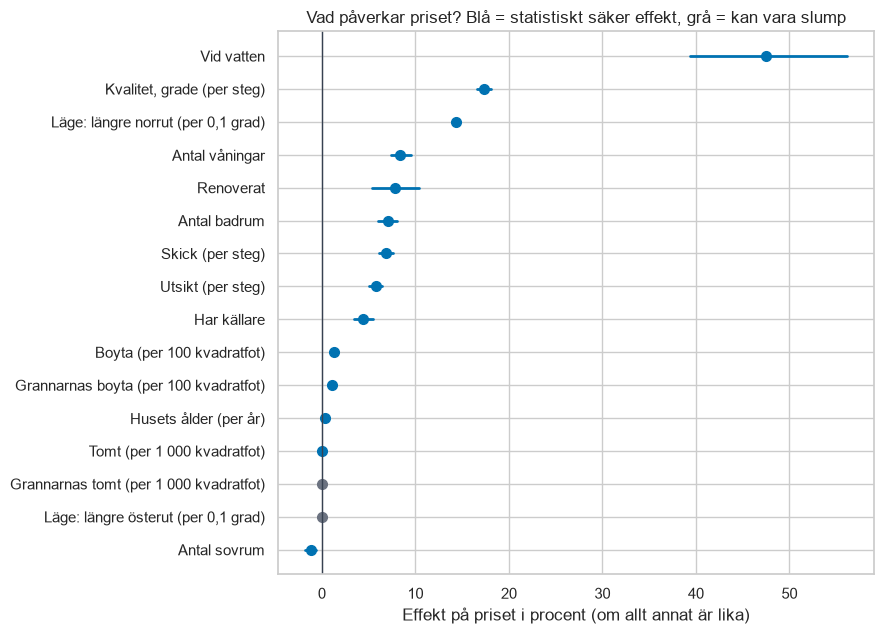

In [20]:
# Forest plot: varje rad är en egenskap. Punkten är effekten, strecket är konfidensintervallet.
plot = effekt.sort_values("Effekt på pris (%)")
signifikant = plot["p-värde"] < 0.05                  # True/False: är effekten signifikant?
färger = np.where(signifikant, BLÅ, GRÅ)              # blå = signifikant, grå = inte signifikant

fig, ax = plt.subplots(figsize=(9, 6.5))
y_pos = np.arange(len(plot))
for i, (värde, lo_, hi_, c) in enumerate(zip(plot["Effekt på pris (%)"], plot["Nedre (95 %)"], plot["Övre (95 %)"], färger)):
    ax.plot([lo_, hi_], [i, i], color=c, linewidth=2)             # konfidensintervallet
    ax.plot(värde, i, "o", color=c, markersize=7)                 # själva effekten
ax.axvline(0, color="#374151", linewidth=1)                       # noll = ingen effekt
ax.set_yticks(y_pos)
ax.set_yticklabels(plot.index)
ax.set_xlabel("Effekt på priset i procent (om allt annat är lika)")
ax.set_title("Vad påverkar priset? Blå = statistiskt säker effekt, grå = kan vara slump")
plt.tight_layout()
plt.show()

**Hur läser vi diagrammet?** Varje punkt är hur många procent priset ändras när egenskapen ökar ett steg, om allt annat är lika. Strecket är det 95-procentiga konfidensintervallet. Om strecket **inte** korsar noll-linjen är effekten statistiskt säker.

**Viktigaste fynden:**
- **Vid vatten: ca +48 %.** Den i särklass största effekten (intervallet ligger ungefär mellan +39 % och +56 %).
- **Kvalitet (grade): ca +17 % per steg.** Ett steg högre byggkvalitet betyder nästan en femtedel högre pris.
- **Läge:** hus längre norrut är dyrare (ca +14 % per 0,1 grad, ungefär 11 km). Det speglar att de dyra områdena ligger i norra delen av countyt.
- **Våningar ca +8 %, renoverat ca +8 %, badrum ca +7 %, skick ca +7 %, utsikt ca +6 % per steg.**
- **Boyta: ca +1,3 % per 100 kvadratfot** (ungefär 9 kvadratmeter), om allt annat är lika.
- **Antal sovrum har en liten *negativ* effekt (ca -1 %).** Det låter konstigt men är logiskt: när boytan är given betyder fler sovrum mindre rum, vilket köpare värderar lägre. Det visar varför man måste tolka effekter "om allt annat är lika".
- **Östra-västra läget (`long`) och grannarnas tomt (`sqft_lot15`) är inte statistiskt säkra** (grå). Läget fångas redan av latituden och övriga variabler.

## 8. Kontroll av antagandena

Statistiska modeller bygger på antaganden. Om de inte håller kan p-värden och intervall bli missvisande. Vi kontrollerar tre saker:
1. **Normalfördelade fel** (Q-Q-plot): ligger punkterna nära linjen?
2. **Lika spridning överallt** (residualplot och Breusch-Pagan-test): är felen lika stora för billiga och dyra hus?
3. **Överlappande variabler** (VIF): mäter två variabler nästan samma sak?

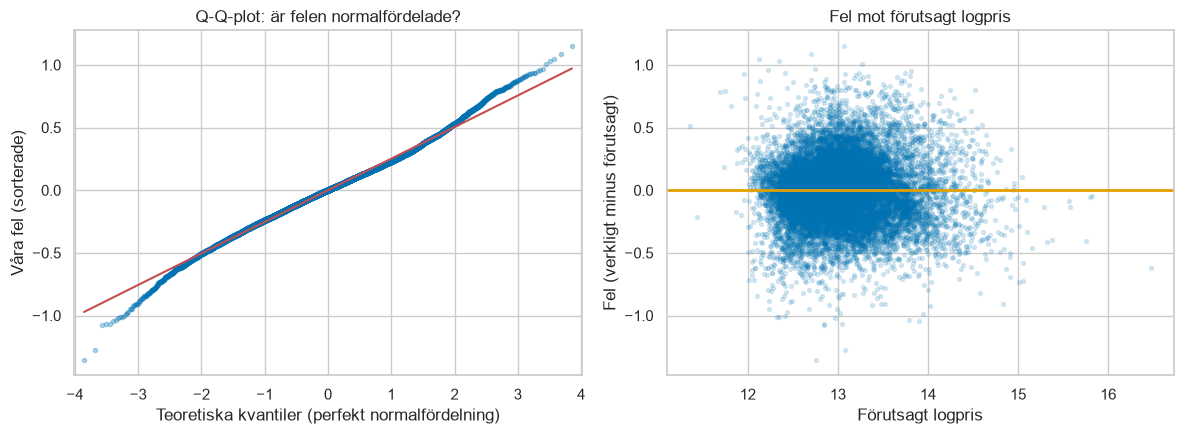

Breusch-Pagan p-värde: 1.77e-149

Högsta VIF-värden:
sqft_living      5.2
bathrooms        3.4
grade            3.3
sqft_living15    2.9
house_age        2.4


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) Q-Q-plot: jämför våra fel med en perfekt normalfördelning. Punkter på linjen = normalfördelade.
sm.qqplot(ols.resid, line="s", ax=axes[0], markerfacecolor=BLÅ, markeredgecolor=BLÅ, alpha=0.3, markersize=3)
axes[0].set_title("Q-Q-plot: är felen normalfördelade?")
axes[0].set_xlabel("Teoretiska kvantiler (perfekt normalfördelning)")
axes[0].set_ylabel("Våra fel (sorterade)")

# 2) Residualer mot förutsagt värde: ska se ut som ett jämnt band runt noll
axes[1].scatter(ols.fittedvalues, ols.resid, alpha=0.15, s=8, color=BLÅ)
axes[1].axhline(0, color=ORANGE, linewidth=2)
axes[1].set_title("Fel mot förutsagt logpris")
axes[1].set_xlabel("Förutsagt logpris")
axes[1].set_ylabel("Fel (verkligt minus förutsagt)")
plt.tight_layout()
plt.show()

# Breusch-Pagan: testar om spridningen i felen är lika överallt. Lågt p-värde = ojämn spridning.
bp_p = het_breuschpagan(ols.resid, X_train_ols)[1]
print(f"Breusch-Pagan p-värde: {bp_p:.2e}")

# VIF: över ca 10 betyder att en variabel till stor del förklaras av de andra
vif = pd.Series(
    [variance_inflation_factor(X_train_ols.values, i) for i in range(X_train_ols.shape[1])],
    index=X_train_ols.columns,
).drop("const").sort_values(ascending=False)
print("\nHögsta VIF-värden:")
print(vif.head(5).round(1).to_string())

**Tolkning:**
- **Normalfördelning:** Q-Q-plotten följer linjen i mitten men avviker i ändarna, så det finns fler extrema fel än en perfekt normalfördelning. Med så många observationer är det inget stort problem för effekternas storlek.
- **Spridning:** Breusch-Pagan-testet visar **ojämn spridning** (p-värdet är i praktiken noll). Därför valde vi **robusta standardfel (HC3)**, som är byggda för just det. Effekterna är desamma, men intervallen är ärliga.
- **Överlappande variabler:** Det högsta VIF-värdet är ca 5, långt under gränsen 10. Det beror på att vi tog bort `sqft_above` och `sqft_basement` (som tillsammans är exakt lika med `sqft_living`). Inga variabler behöver tas bort.

**Det här är en begränsning att nämna:** regressionen antar att effekterna adderas på ett jämnt sätt. I verkligheten samspelar variabler (läge och storlek påverkar varandra), och det kan en enkel regression inte fånga fullt ut.

## 9. Modell 2: Random Forest

**Liknelse:** Tänk dig att vi ber 200 olika husvärderare uppskatta priset. Var och en har bara fått titta på ett slumpmässigt urval av husen och egenskaperna, och kommer fram till sin egen gissning. Sedan tar vi **medelvärdet av alla gissningar**.

- **Ett beslutsträd** ställer ja/nej-frågor om huset, till exempel *är kvaliteten över 9? Ligger huset långt norrut? Är boytan över 2 000 kvadratfot?* Svaren leder fram till en prisgissning.
- **Ett enskilt träd** blir lätt för specialiserat på träningsdatan.
- **En skog med 200 träd** jämnar ut felen, eftersom enskilda dåliga gissningar tar ut varandra.

**Varför passar det vårt problem?** Huspriser följer inte raka linjer, och egenskaper samspelar: läget spelar olika stor roll för ett litet och ett stort hus. Random Forest hittar sådana samband av sig själv, utan att vi behöver ange dem.

In [22]:
# Skapa och träna Random Forest med 200 träd.
# random_state=42 ger samma resultat varje gång. n_jobs=-1 använder alla processorkärnor (snabbare).
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)     # "fit" = modellen lär sig av träningsdatan
print("Random Forest tränad på", len(X_train), "hus.")

Random Forest tränad på 17289 hus.


### Korsvalidering: hur vet vi att resultatet inte bara var tur?

Vi delar träningsdatan i **5 lika stora delar**, tränar på 4 och testar på den femte, och upprepar det 5 gånger så att varje del får vara "prov" en gång. Liknande värden i alla omgångar betyder att modellen är stabil. Testdatan rör vi inte här, den sparas till slutprovet.

In [23]:
# Korsvalidering med 5 delar (cv=5). scoring="r2" mäter hur stor del av variationen modellen förklarar.
cv_r2 = cross_val_score(rf, X_train, y_train, cv=5, scoring="r2", n_jobs=-1)

print("R² per omgång:", cv_r2.round(3))
print(f"Medelvärde: {cv_r2.mean():.3f}   Lägsta: {cv_r2.min():.3f}   Högsta: {cv_r2.max():.3f}")

R² per omgång: [0.865 0.881 0.88  0.885 0.864]
Medelvärde: 0.875   Lägsta: 0.864   Högsta: 0.885


**Tolkning:** De fem omgångarna ger R² mellan ca 0,86 och 0,89 (medel ca 0,88), alltså mycket lika varandra. Modellen är **stabil**, och resultatet berodde inte på vilka hus som råkade hamna var.

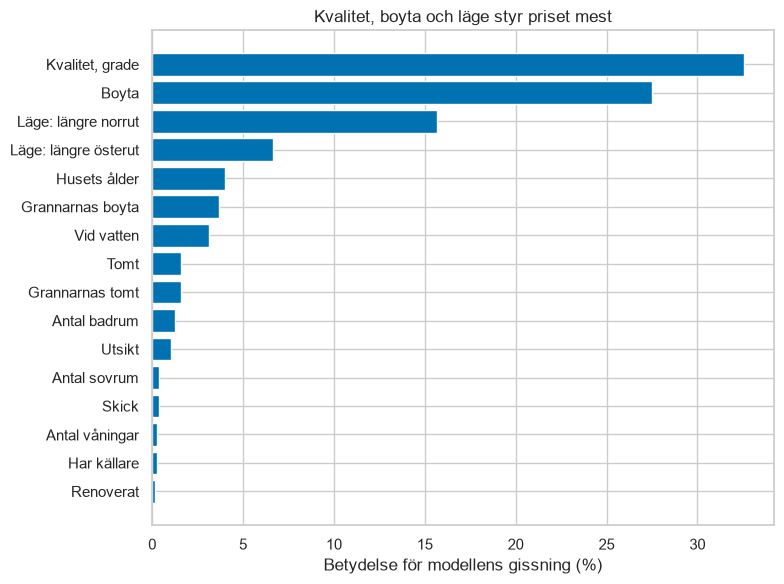

In [24]:
# Feature importance: hur mycket använder skogens träd varje variabel när de delar upp husen?
viktighet = pd.Series(rf.feature_importances_, index=features).sort_values()
viktighet.index = [namn[i].split(" (")[0] for i in viktighet.index]   # svenska namn, utan enheten i parentes

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(viktighet.index, viktighet.values * 100, color=BLÅ)
ax.set_xlabel("Betydelse för modellens gissning (%)")
ax.set_title("Kvalitet, boyta och läge styr priset mest")
plt.tight_layout()
plt.show()

**Tolkning:** Tre faktorer dominerar: **kvalitet (grade)**, **boyta** och **läge** (latitud och longitud). Tillsammans står de för merparten av modellens beslut. Det stämmer med regressionen, som också pekade ut kvalitet, läge och vatten som starka effekter. Obs: feature importance säger *hur mycket* en variabel används, inte *åt vilket håll* den påverkar priset. Det visar regressionen.

## 10. Resultat på testdatan

Nu är det dags för slutprovet. Båda modellerna får gissa priset på de 4 323 hus i testdatan som de aldrig har sett. Vi jämför gissningarna med de verkliga priserna.

**Så mäter vi:**
- **R²:** hur stor andel av prisvariationen modellen förklarar (närmare 1 är bättre).
- **MAE:** hur många dollar modellen missar med i genomsnitt.
- **RMSE:** som MAE, men stora misstag straffas hårdare.
- **Typiskt fel i procent (median):** hur många procent fel modellen har för ett typiskt hus. Lättast att förklara för en kund.

In [25]:
# OLS gissar logpriset, så vi räknar tillbaka med exp() för att få dollar
pred_ols = np.exp(ols.predict(sm.add_constant(skala(X_test))))

# Random Forest gissar priset direkt
pred_rf = rf.predict(X_test)

def utvärdera(p):
    # Räknar ut alla mått för en modells gissningar p jämfört med de verkliga priserna y_test
    fel_procent = np.abs(y_test - p) / y_test            # felet som andel av verkligt pris
    return {
        "R² (pris)": r2_score(y_test, p),
        "R² (logpris)": r2_score(np.log(y_test), np.log(p)),
        "MAE (USD)": mean_absolute_error(y_test, p),
        "RMSE (USD)": np.sqrt(mean_squared_error(y_test, p)),
        "Typiskt fel (%)": fel_procent.median() * 100,
    }

# Samla resultaten i en tabell: en rad per modell
resultat = pd.DataFrame({
    "Linjär regression (OLS)": utvärdera(pred_ols),
    "Random Forest": utvärdera(pred_rf),
}).T
resultat.round(3)

,R² (pris),R² (logpris),MAE (USD),RMSE (USD),Typiskt fel (%)
Linjär regression (OLS),0.535,0.769,116648.769,264160.124,15.720
Random Forest,0.862,0.888,72184.281,144159.639,8.778


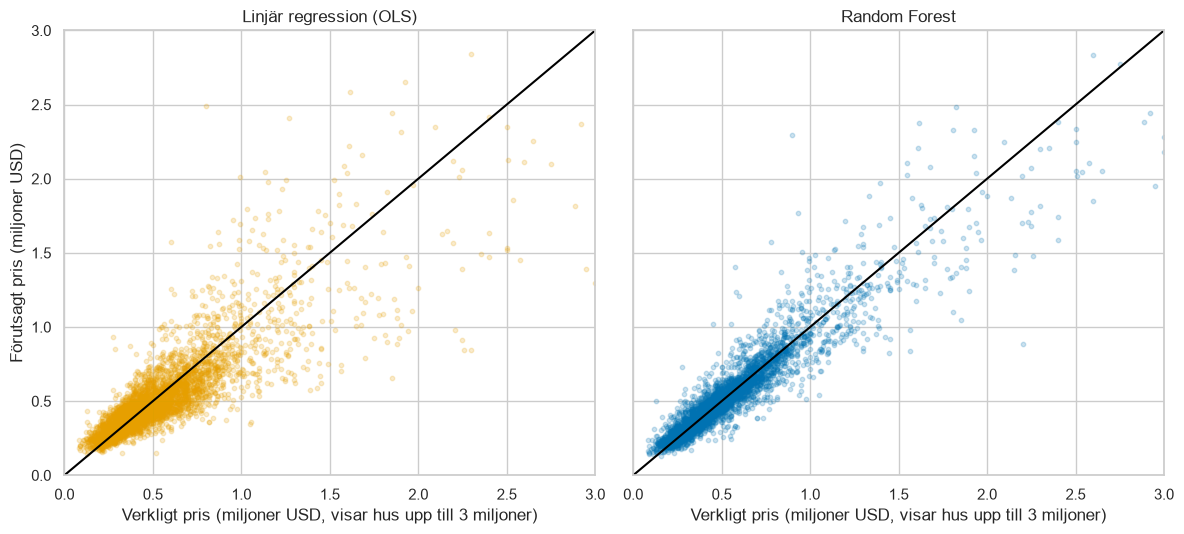

In [26]:
# Verkligt pris mot förutsagt pris för båda modellerna. Punkter nära den svarta linjen = bra gissning.
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
gräns = [0, 3.0e6]                     # vi zoomar till 0-3 miljoner för att se huvuddelen av husen

for ax, (titel, p, färg) in zip(axes, [("Linjär regression (OLS)", pred_ols, ORANGE),
                                       ("Random Forest", pred_rf, BLÅ)]):
    ax.scatter(y_test, p, alpha=0.2, s=10, color=färg)
    ax.plot(gräns, gräns, color="black", linewidth=1.5)   # perfekt gissning: förutsagt = verkligt
    ax.set_xlim(gräns); ax.set_ylim(gräns)
    ax.xaxis.set_major_formatter(FuncFormatter(miljoner))
    ax.yaxis.set_major_formatter(FuncFormatter(miljoner))
    ax.set_title(titel)
    ax.set_xlabel("Verkligt pris (miljoner USD, visar hus upp till 3 miljoner)")
axes[0].set_ylabel("Förutsagt pris (miljoner USD)")
plt.tight_layout()
plt.show()

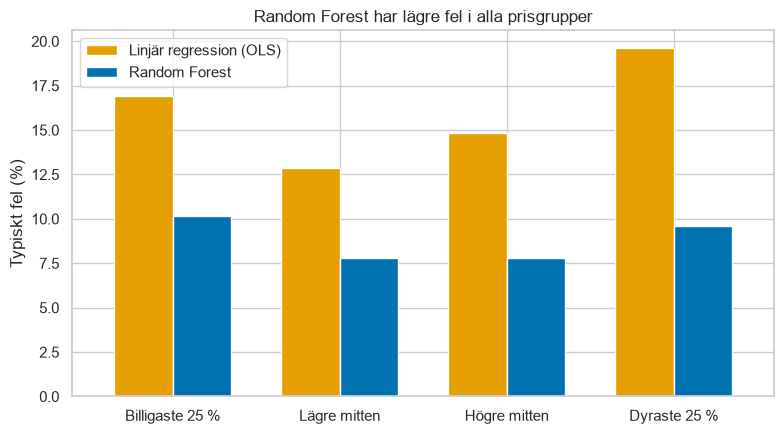

,OLS: MAE (USD),Random Forest: MAE (USD)
price,,
Billigaste 25 %,55486.0,39330.0
Lägre mitten,61427.0,43162.0
Högre mitten,94136.0,58862.0
Dyraste 25 %,255980.0,147621.0


In [27]:
# Var gör modellerna störst fel? Dela testhusen i fyra lika stora prisgrupper (kvartiler).
grupper = pd.qcut(y_test, 4, labels=["Billigaste 25 %", "Lägre mitten", "Högre mitten", "Dyraste 25 %"])

# Typiskt fel i procent per prisgrupp, för båda modellerna
fel_per_grupp = pd.DataFrame({
    "Linjär regression (OLS)": (np.abs(y_test - pred_ols) / y_test).groupby(grupper, observed=True).median() * 100,
    "Random Forest": (np.abs(y_test - pred_rf) / y_test).groupby(grupper, observed=True).median() * 100,
})

ax = fel_per_grupp.plot(kind="bar", color=[ORANGE, BLÅ], figsize=(8, 4.5), rot=0, width=0.7)
ax.set_title("Random Forest har lägre fel i alla prisgrupper")
ax.set_xlabel("")
ax.set_ylabel("Typiskt fel (%)")
ax.legend(title="")
plt.tight_layout()
plt.show()

# Genomsnittligt fel i dollar per prisgrupp
pd.DataFrame({
    "OLS: MAE (USD)": np.abs(y_test - pred_ols).groupby(grupper, observed=True).mean(),
    "Random Forest: MAE (USD)": np.abs(y_test - pred_rf).groupby(grupper, observed=True).mean(),
}).round(0)

In [28]:
# Konkreta exempel: fem slumpvis valda hus ur testdatan. Hur nära kom modellerna?
urval = X_test.sample(5, random_state=1).index          # fem slumpade rader (samma varje gång)

exempel = pd.DataFrame({
    "Boyta (kvfot)": X_test.loc[urval, "sqft_living"],
    "Kvalitet (grade)": X_test.loc[urval, "grade"],
    "Vid vatten": X_test.loc[urval, "waterfront"].map({0: "Nej", 1: "Ja"}),
    "Verkligt pris": y_test.loc[urval],
    "OLS gissar": pred_ols.loc[urval],
    "Random Forest gissar": pd.Series(pred_rf, index=X_test.index).loc[urval],
})
exempel["Fel RF (%)"] = (exempel["Random Forest gissar"] / exempel["Verkligt pris"] - 1) * 100
exempel.round(0).astype({"Verkligt pris": int, "OLS gissar": int, "Random Forest gissar": int})

,Boyta (kvfot),Kvalitet (grade),Vid vatten,Verkligt pris,OLS gissar,Random Forest gissar,Fel RF (%)
3169,1720,7,Nej,575000,591463,640123,11.0
5929,3330,10,Nej,762500,1083216,829128,9.0
6281,2280,8,Nej,760000,581610,656308,-14.0
21096,3040,9,Nej,431000,464734,423703,-2.0
12117,1830,7,Nej,585000,462222,525114,-10.0


### Tolkning av resultaten

| Mått (testdata) | Linjär regression (OLS) | Random Forest |
|---|---|---|
| R² (pris) | ca 0,54 | ca 0,86 |
| R² (logpris) | ca 0,77 | ca 0,89 |
| MAE | ca 117 000 USD | ca 72 000 USD |
| RMSE | ca 264 000 USD | ca 144 000 USD |
| Typiskt fel | ca 16 % | ca 9 % |

**Vilken modell är bäst på att förutsäga?** **Random Forest**, tydligt. Den missar i genomsnitt med ca 72 000 USD jämfört med ca 117 000 USD för regressionen, och ett typiskt hus får ca 9 % fel jämfört med ca 16 %. Medianpriset i testdatan är ca 450 000 USD, så ett genomsnittligt fel på ca 72 000 USD motsvarar ungefär 16 % av ett typiskt pris.

**Varför är regressionen sämre i dollar?** OLS förklarar 77 % av variationen i *logpriset* men bara 54 % av variationen i *dollarpriset*. Skillnaden beror på att små fel i procent blir stora fel i dollar för de dyraste husen (se diagrammet över fel per prisgrupp), och på att regressionen antar raka, additiva samband medan verkligheten har samspel, framför allt mellan läge, storlek och kvalitet. Random Forest hittar sådana samband själv.

**Men OLS är inte onödig.** Random Forest är bättre på att *gissa*, men den kan inte säga att "vatten ger ca +48 %" eller hur säkra vi är på det. Det kan regressionen. Därför använder vi dem tillsammans: **Random Forest för prisförslaget, regressionen för förklaringen till kunden.**

## 11. Slutsats

**Vad lärde vi oss?**
- **Statistiskt:** Hus vid vatten är ca 48 % dyrare, varje steg högre kvalitet ger ca 17 % högre pris, och läget spelar stor roll, allt annat lika. Skillnaderna är verkliga och inte slump (hypotestest och konfidensintervall).
- **Prediktivt:** Random Forest förutsäger priset på nya hus med ett typiskt fel på ca 9 % (ca 72 000 USD i genomsnitt) och R² på ca 0,86 på testdata. Korsvalideringen visar att resultatet är stabilt.

**Vad betyder det för SaMiJeShi Estates?**
Modellen kan ge våra kunder ett **snabbt, konsekvent första prisförslag**, som en värderare sedan kan finjustera. Regressionen ger oss ett **förklarbart underlag**: vi kan visa kunden vad som driver priset och hur säkra vi är. Det sparar tid och minskar skillnaderna mellan olika värderares bedömningar.

**Begränsningar:**
- **Gammal data.** Försäljningarna är från 2014 till 2015, så modellen speglar inte dagens marknad och måste tränas om på nyare data.
- **Dyra hus är svårare.** Det finns få dyra hus i datan, och felet i dollar är störst för den dyraste fjärdedelen.
- **Saknade faktorer.** Modellen känner inte till husets inredning, exakta skick, tomtens egenskaper eller kvarterets känsla.
- **Antaganden i regressionen.** Felens spridning är ojämn (vi hanterade det med robusta standardfel) och regressionen fångar inte samspel mellan variabler fullt ut.
- **Samband är inte orsakssamband.** Att hus vid vatten kostar ca 48 % mer betyder inte att vattnet ensamt "orsakar" hela skillnaden, eftersom dessa hus även skiljer sig på andra sätt.
- **Dubbelsålda hus.** 177 hus finns med två försäljningar. De kan ligga i både tränings- och testdata, vilket kan göra resultatet något för optimistiskt.

**Nästa steg: från prediktiv till preskriptiv analys**
Idag förutsäger modellen ett pris. Nästa steg är att låta den **rekommendera åtgärder**, till exempel vilken renovering som ger störst prisökning i förhållande till kostnaden, eller vilket utgångspris som ger snabbast försäljning. Vi kan även testa fler modeller (Gradient Boosting, XGBoost), lägga till nyare data och beräkna **osäkerhetsintervall** runt varje prisförslag.

*Tack för oss! /Jessika, Saji, Shiann och Milena, SaMiJeShi Estates*